# Projekt: Wstępne przetwarzanie danych - zbiór Titanic
**Cel:** Oczyszczenie danych, stworzenie nowych cech (feature engineering) i przygotowanie Pipeline'u pod model klasyfikacyjny. Szczególny nacisk na to, aby uniknąć wycieku danych z testowego do treningowego.

źródło: https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# df = pd.read_csv('https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv')
df = pd.read_csv("titanic.csv")
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


## 1. Oględziny i braki danych
Szybki rzut oka na typy zmiennych i weryfikacja kompletności.

In [12]:
df.info()

print("\n\nKompletność procent braków:")
missing_data = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({'Braki': missing_data, 'Procent (%)': missing_percent})
display(missing_df[missing_df['Braki'] > 0].sort_values(by='Procent (%)', ascending=False))

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


Kompletność procent braków:


,Braki,Procent (%)
Cabin,687,77.104377
Age,177,19.865320
Embarked,2,0.224467


### Wnioski:

- Cabin (>77% braków) - kwalifikuje się do usunięcia lub zmiany na flagę

- Age (~20% braków) - zastosujemy imputację grupową

- Embarked (<1% braków) - prosta imputacja modą

## 2. Podgląd rozkładów
Sprawdzam, jak wyglądają rozkłady, żeby wyłapać ewentualne wartości skrajne (outliery).

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


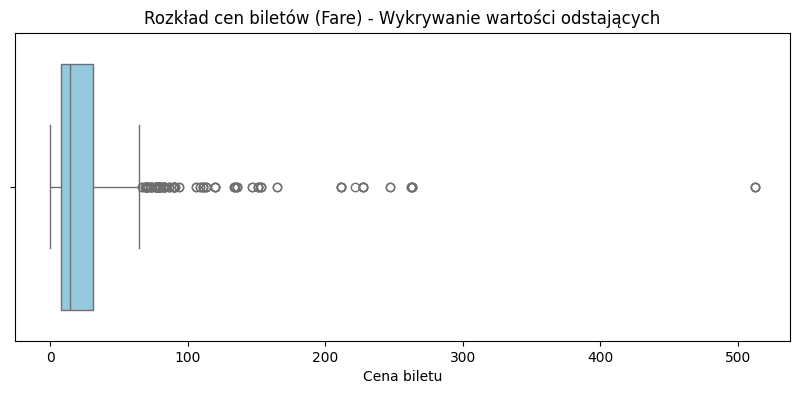

In [13]:
display(df.describe())

# Wizualizacja ceny
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['Fare'], color='skyblue')
plt.title('Rozkład cen biletów (Fare) - Wykrywanie wartości odstających')
plt.xlabel('Cena biletu')
plt.show()



Mocne skrzywienie w prawo i wyraźne outliery (np. bilet za ponad 500). Bez odpowiedniego skalera algorytmy oparte na dystansie na pewno miałyby tu problem.

## 3. Ekstrakcja nowych cech
Wyciskam z danych trochę więcej użytecznych informacji (np. z imion i liczby krewnych).

In [14]:
data = df.copy()
data['Title'] = data['Name'].str.extract(' ([A-Za-z]+)\\.', expand=False)

# Łączenie tytułów
otherTitles = ['Lady', 'Countess','Capt', 'Col', 'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona']
data['Title'] = data['Title'].replace(otherTitles, 'Other')
data['Title'] = data['Title'].replace('Mlle', 'Miss')
data['Title'] = data['Title'].replace('Ms', 'Miss')
data['Title'] = data['Title'].replace('Mme', 'Mrs')

print("Rozkład nowych tytułów pasażerów:")
print(data['Title'].value_counts())

# Rodziny
data['FamilySize'] = data['SibSp'] + data['Parch'] + 1

data['IsAlone'] = 0
data.loc[data['FamilySize'] == 1, 'IsAlone'] = 1

# Kabiny
data['Has_Cabin'] = data['Cabin'].apply(lambda x: 0 if type(x) == float else 1)

data[['Name', 'Title', 'FamilySize', 'IsAlone', 'Has_Cabin']]

Rozkład nowych tytułów pasażerów:
Title
Mr        517
Miss      185
Mrs       126
Master     40
Other      23
Name: count, dtype: int64


,Name,Title,FamilySize,IsAlone,Has_Cabin
0,"Braund, Mr. Owen Harris",Mr,2,0,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,2,0,1
2,"Heikkinen, Miss. Laina",Miss,1,1,0
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,2,0,1
4,"Allen, Mr. William Henry",Mr,1,1,0
...,...,...,...,...,...
886,"Montvila, Rev. Juozas",Other,1,1,0
887,"Graham, Miss. Margaret Edith",Miss,1,1,1
888,"Johnston, Miss. Catherine Helen ""Carrie""",Miss,4,0,0
889,"Behr, Mr. Karl Howell",Mr,1,1,1


## 4. Imputacja Age i podział zbioru
Braki w `Age` łatamy medianą grupową na podstawie tytułów z imion. Następnie odcinam wektory X i y oraz robię `train_test_split`, żeby uniknąć wycieku danych przy dalszym procesowaniu.

In [15]:
age_medians = data.groupby('Title')['Age'].transform('median')
data['Age'] = data['Age'].fillna(age_medians)

X = data.drop(columns=['PassengerId', 'Survived', 'Name', 'Ticket', 'Cabin'])
y = data['Survived']

# Podział na zbiór treningowy i walidacyjny
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=2026, stratify=y)

print(f"Rozmiar zbioru treningowego: {X_train.shape}")
print(f"Rozmiar zbioru walidacyjnego: {X_val.shape}")

Rozmiar zbioru treningowego: (712, 11)
Rozmiar zbioru walidacyjnego: (179, 11)


## 5. Złożenie Pipeline'u
OHE dla kategorii, StandardScaler dla cech numerycznych. Całość wpinam w Pipeline i odpalam `.fit()` tylko na trainie.

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer


num_features = ['Age', 'Fare', 'FamilySize']
cat_features = ['Sex', 'Embarked', 'Title']
passthrough_features = ['Pclass', 'IsAlone', 'Has_Cabin']

# cechy numeryczne
num_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])

# cechy kategoryczne
cat_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))])

preprocessor = ColumnTransformer(transformers=[('num', num_transformer, num_features), ('cat', cat_transformer, cat_features), ('pass', 'passthrough', passthrough_features)])

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

encoded_cat_names = preprocessor.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_features)
all_feature_names = num_features + list(encoded_cat_names) + passthrough_features

X_train_ready = pd.DataFrame(X_train_processed, columns=all_feature_names)
display(X_train_ready.head())

,Age,Fare,FamilySize,Sex_male,Embarked_Q,Embarked_S,Title_Miss,Title_Mr,Title_Mrs,Title_Other,Pclass,IsAlone,Has_Cabin
0,0.013187,-0.619680,-0.553277,1.0,0.0,1.0,0.0,1.0,0.0,0.0,2.0,1.0,0.0
1,-0.443259,4.070486,0.081076,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
2,-0.138962,0.005623,0.081076,1.0,0.0,1.0,0.0,0.0,0.0,1.0,2.0,0.0,0.0
3,-0.138962,-0.379981,-0.553277,0.0,0.0,1.0,0.0,0.0,1.0,0.0,2.0,1.0,0.0
4,2.067193,-0.385665,-0.553277,1.0,1.0,0.0,0.0,0.0,0.0,1.0,2.0,1.0,0.0


## 6. Korelacja i selekcja cech
Sprawdzam macierz korelacji na gotowym zbiorze treningowym (`X_train_ready`). Zamiast redukcji przez PCA wolę ręcznie podejrzeć zależności i wyrzucić nadmiarowe zmienne, żeby model był łatwiejszy w interpretacji.

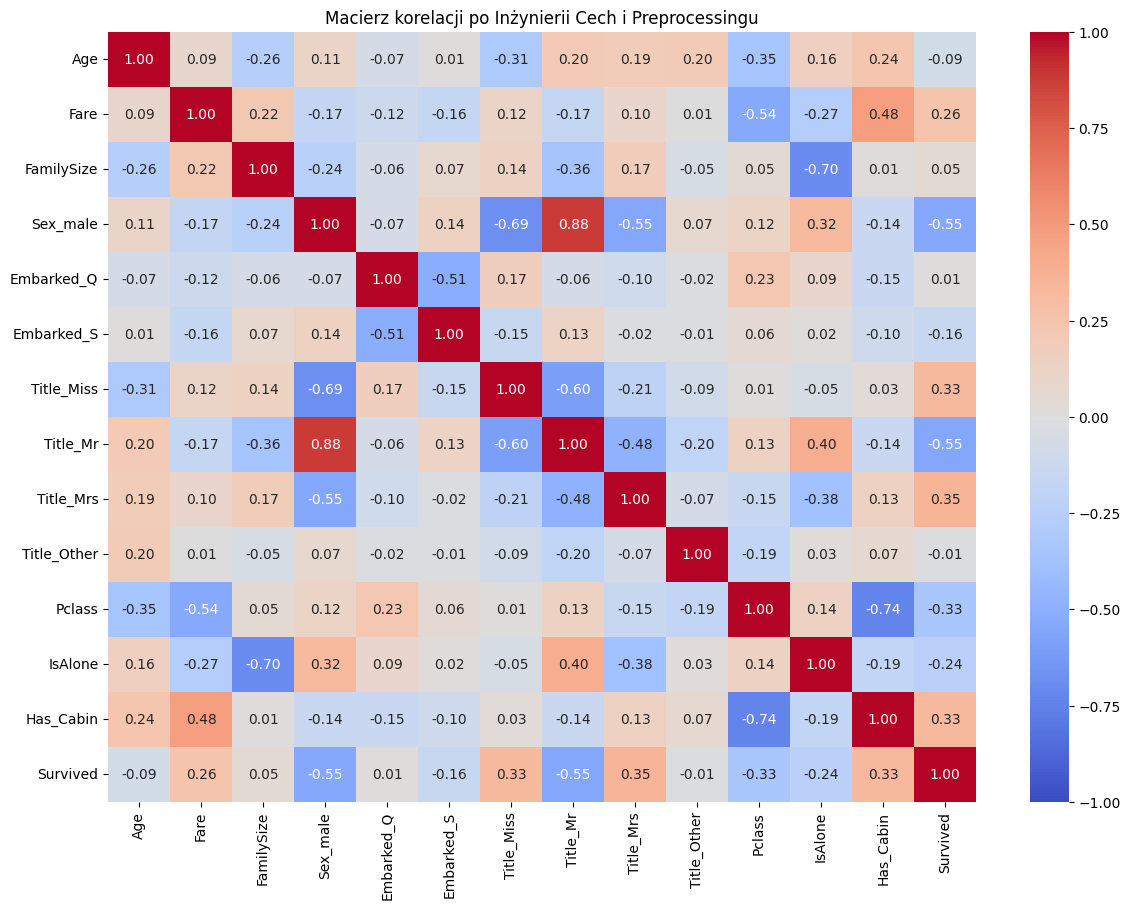

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

X_train_corr = X_train_ready.copy()
X_train_corr['Survived'] = y_train.reset_index(drop=True)

corr_matrix = X_train_corr.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Macierz korelacji po Inżynierii Cech i Preprocessingu')
plt.show()

**Szybkie wnioski z korelacji:**
* `Title_Mr` i `Sex_female` najmocniej korelują z przetrwaniem (co potwierdza historyczną regułę "kobiety i dzieci przodem").
* `FamilySize` i `IsAlone` mówią praktycznie to samo (silna współliniowość). Dla Random Forest to nie problem, ale przy modelach liniowych jedną na pewno trzeba by wyrzucić.
* `Pclass` i `Fare` są mocno ujemnie skorelowane (im niższy numer klasy, tym droższy bilet – w pełni logiczne).

## 7. Ostateczny model (Random Forest)
Spinamy `ColumnTransformer` z klasyfikatorem w jeden główny Pipeline. Dzięki temu będę mógł od razu przepuścić surowe dane z `test.csv` przez model bez konieczności ręcznego odtwarzania każdego kroku na nowo.

--- Wyniki Modelu (Random Forest) ---
Dokładność (Accuracy): 0.8268

Raport Klasyfikacji:
              precision    recall  f1-score   support

           0       0.83      0.90      0.86       110
           1       0.82      0.71      0.76        69

    accuracy                           0.83       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.83      0.83      0.82       179



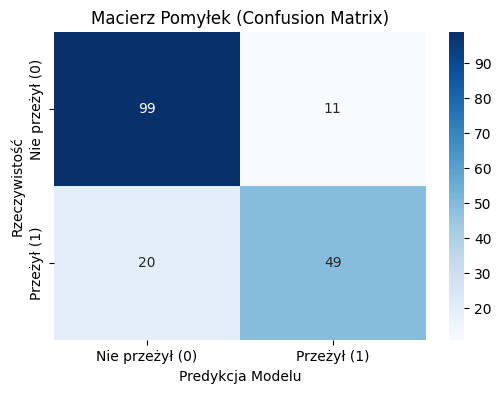

In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


full_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', RandomForestClassifier(n_estimators=100, max_depth=5, random_state=2026))])

full_pipeline.fit(X_train, y_train)

y_pred = full_pipeline.predict(X_val)

print("--- Wyniki Modelu (Random Forest) ---")
print(f"Dokładność (Accuracy): {accuracy_score(y_val, y_pred):.4f}\n")
print("Raport Klasyfikacji:")
print(classification_report(y_val, y_pred))

conf_mat = confusion_matrix(y_val, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues', xticklabels=['Nie przeżył (0)', 'Przeżył (1)'], yticklabels=['Nie przeżył (0)', 'Przeżył (1)'])
plt.ylabel('Rzeczywistość')
plt.xlabel('Predykcja Modelu')
plt.title('Macierz Pomyłek (Confusion Matrix)')
plt.show()

## 8. Co okazało się najważniejsze? (Feature Importance)

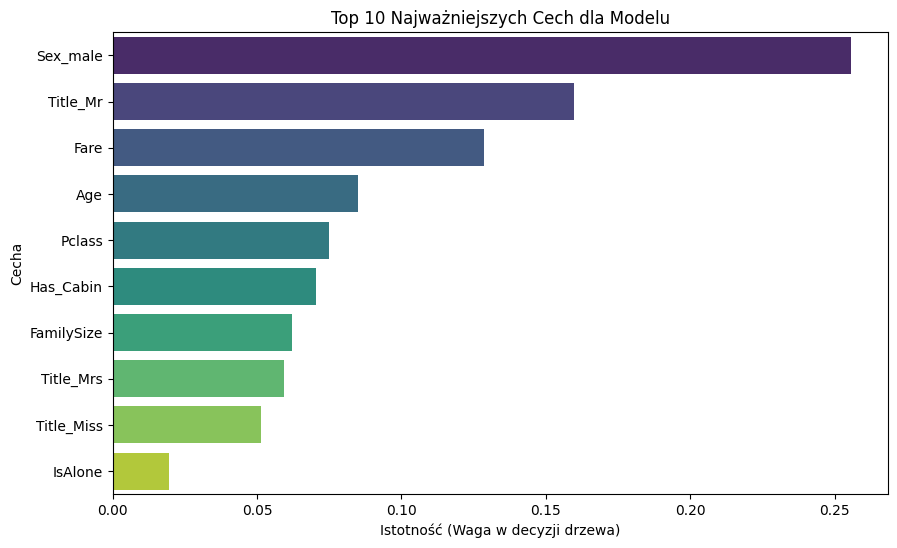

In [19]:
trained_model = full_pipeline.named_steps['classifier']

importances = trained_model.feature_importances_

feature_importance_df = pd.DataFrame({'Cecha': all_feature_names,'Istotność': importances}).sort_values(by='Istotność', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Istotność', y='Cecha', hue='Cecha', data=feature_importance_df.head(10), palette='viridis', legend=False)
plt.title('Top 10 Najważniejszych Cech dla Modelu')
plt.xlabel('Istotność (Waga w decyzji drzewa)')
plt.ylabel('Cecha')
plt.show()

## 9. Gdzie model się myli? (Error Analysis)

In [20]:

error_analysis_df = X_val.copy()

error_analysis_df['Rzeczywistosc'] = y_val
error_analysis_df['Predykcja'] = y_pred

bledy = error_analysis_df[error_analysis_df['Rzeczywistosc'] != error_analysis_df['Predykcja']]

print(f"Model popełnił łącznie {len(bledy)} błędów na {len(X_val)} pasażerów w zbiorze walidacyjnym.\n")

# False Positives
false_positives = bledy[(bledy['Predykcja'] == 1) & (bledy['Rzeczywistosc'] == 0)]
print("--- Przykład: Pasażerowie, którzy mieli przeżyć, ale zginęli (False Positives) ---")
display(false_positives[['Pclass', 'Sex', 'Age', 'Fare', 'Title', 'FamilySize']])

# False Negatives
false_negatives = bledy[(bledy['Predykcja'] == 0) & (bledy['Rzeczywistosc'] == 1)]
print("\n--- Przykład: Pasażerowie, którzy mieli zginąć, ale przeżyli (False Negatives) ---")
display(false_negatives[['Pclass', 'Sex', 'Age', 'Fare', 'Title', 'FamilySize']])

Model popełnił łącznie 31 błędów na 179 pasażerów w zbiorze walidacyjnym.

--- Przykład: Pasażerowie, którzy mieli przeżyć, ale zginęli (False Positives) ---


,Pclass,Sex,Age,Fare,Title,FamilySize
593,3,female,21.0,7.7500,Miss,3
49,3,female,18.0,17.8000,Mrs,2
312,2,female,26.0,26.0000,Mrs,3
245,1,male,44.0,90.0000,Other,3
807,3,female,18.0,7.7750,Miss,1
654,3,female,18.0,6.7500,Miss,1
205,3,female,2.0,10.4625,Miss,2
41,2,female,27.0,21.0000,Mrs,2
113,3,female,20.0,9.8250,Miss,2
111,3,female,14.5,14.4542,Miss,2



--- Przykład: Pasażerowie, którzy mieli zginąć, ale przeżyli (False Negatives) ---


,Pclass,Sex,Age,Fare,Title,FamilySize
400,3,male,39.0,7.9250,Mr,1
630,1,male,80.0,30.0000,Mr,1
484,1,male,25.0,91.0792,Mr,2
569,3,male,32.0,7.8542,Mr,1
271,3,male,25.0,0.0000,Mr,1
762,3,male,20.0,7.2292,Mr,1
370,1,male,25.0,55.4417,Mr,2
553,3,male,22.0,7.2250,Mr,1
220,3,male,16.0,8.0500,Mr,1
283,3,male,19.0,8.0500,Mr,1


**Notatki z analizy błędów:**
* **False Positives (przewidział przeżycie, a zginęli):** Wyróżniają się tu kobiety z 3. klasy. Model "ślepo" poleciał na cechę płci (`Sex_female`), nie łapiąc kontekstu, że w 3. klasie płeć miała znacznie mniejsze znaczenie przy ogólnym braku dostępu do szalup.
* **False Negatives (przewidział śmierć, a przeżyli):** Tu głównie wpadli mężczyźni podróżujący z rodziną lub z droższym biletem. Model z góry założył u nich najgorsze przez silną zmienną `Sex_male`.
* **Pomysł na przyszłość:** Żeby to poprawić, można by było w inżynierii cech stworzyć nową kolumnę zbitkę (np. `Klasa_Płeć` - Kobieta_1_Klasa, Kobieta_3_Klasa). To powinno ułatwić drzewu decyzyjnemu wychwycenie takich niuansów.

**Wnioski i podsumowanie:**
* Udało się spiąć cały preprocessing w `Pipeline`. Dzięki temu unikamy wycieku danych – imputer i scalery "uczą się" tylko na X_train.
* Zamiast wstawiać globalną średnią w brakujący wiek (`Age`), lepsze efekty dała imputacja połączona z tytułami (Mr, Miss, itd.) wyciągniętymi z imion.
* Agregacja kolumn w `FamilySize` oraz prosta flaga `Has_Cabin` to cechy, z którymi model radzi sobie zauważalnie lepiej.
* Zrezygnowałem z PCA. Analiza korelacji i ręczne usunięcie nadmiarowych kolumn były wystarczające, a model (Random Forest) i tak całkiem nieźle radzi sobie ze współliniowością.